# 07 — Localization + Quantification of AI-edited regions

**What this notebook does**
1. **Localization**: predicts a pixel mask of the AI-inpainted region (Flux) in each manipulated image.
2. **Quantification**: estimates *what percentage of the image* is AI-generated, and evaluates that estimate (MAE, RMSE, correlation, bucket accuracy).

**Why it should beat the previous U-Net (val Dice ≈ 0.13)**
| Before (06) | Now (07) |
|---|---|
| U-Net trained from scratch | U-Net with **ImageNet-pretrained ResNet-34** encoder |
| Whole image squashed to 256×256 (destroys generator artefacts, tiny masks become a few pixels) | **Native-resolution 512×512 crops**, 70 % of them centred on the edited region |
| Re-reads PNGs from Drive each epoch | One-time **memory-mapped cache** on the local disk (fast on Colab *and* laptop) |
| Metrics on padded canvas | Metrics on the real image pixels, threshold tuned on validation only |

**v2:** trains/evaluates only on pairs whose mask was verified by `08_Mask_Audit.ipynb` (`CLEAN_LABELS=True`) and adds verified bbox pairs to training.

**Runs unchanged on Colab and on your laptop (RTX 4050 6 GB / 16 GB RAM)** — only cell 2 (`PROJECT_DIR`) may need editing locally.
Training resumes automatically from the last saved epoch if the session dies.

In [1]:
# ============================================================
# 1. Environment + packages
# ============================================================
import os, sys, json, time, math, random, hashlib, subprocess, platform, shutil
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

def ensure(module, pip_name=None):
    try:
        __import__(module)
    except ImportError:
        print(f"Installing {pip_name or module} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name or module])

ensure("segmentation_models_pytorch", "segmentation-models-pytorch")
ensure("sklearn", "scikit-learn")
ensure("scipy")
ensure("pandas")
ensure("matplotlib")
ensure("tqdm")

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import segmentation_models_pytorch as smp

Image.MAX_IMAGE_PIXELS = None
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Python   :", sys.version.split()[0], "| OS:", platform.system(), "| Colab:", IN_COLAB)
print("PyTorch  :", torch.__version__, "| smp:", smp.__version__)
print("Device   :", device)
if device.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    print("GPU      :", props.name, f"| VRAM {props.total_memory/1e9:.1f} GB")
elif IN_COLAB:
    raise RuntimeError("No GPU attached. In Colab: Runtime -> Change runtime type -> T4 GPU, then Run all. "
                       "If the GPU quota is used up, connect Colab to your laptop instead (Connect -> Connect to a local runtime).")
else:
    print("WARNING: no CUDA GPU found. Install the CUDA build of PyTorch — CPU training would take days.")

Python   : 3.12.10 | OS: Windows | Colab: False
PyTorch  : 2.14.1+cu130 | smp: 0.6.0
Device   : cuda
GPU      : NVIDIA GeForce RTX 4050 Laptop GPU | VRAM 6.4 GB


In [2]:
# ============================================================
# 2. Paths + configuration   (EDIT PROJECT_DIR for local runs)
# ============================================================
if IN_COLAB:
    PROJECT_DIR = Path("/content/drive/MyDrive/AI_Image_Project")
    CACHE_DIR   = Path("/content/loc_cache")              # fast local SSD of the Colab VM
else:
    # Folder that contains Partial_AI_5000/, features/, saved_models/, results/
    PROJECT_DIR = Path(os.environ.get("AI_PROJECT_DIR", r"C:\AI_Image_Project"))
    # Keep the cache OUTSIDE Google Drive (it is ~3 GB per 1000 images and must not sync)
    CACHE_DIR   = Path(os.environ.get("AI_CACHE_DIR", str(Path.home() / "ai_image_cache")))

BASE_DIR         = PROJECT_DIR / "Partial_AI_5000"
LOC_FEATURES_DIR = PROJECT_DIR / "features" / "localization"
LOC_MODELS_DIR   = PROJECT_DIR / "saved_models" / "localization"
LOC_RESULTS_DIR  = PROJECT_DIR / "results" / "localization"
for d in [LOC_FEATURES_DIR, LOC_MODELS_DIR, LOC_RESULTS_DIR, CACHE_DIR]:
    d.mkdir(parents=True, exist_ok=True)
assert (BASE_DIR / "pairs.csv").exists(), f"pairs.csv not found under {BASE_DIR} — fix PROJECT_DIR"

CFG = dict(
    SEED            = 42,
    MAX_SIDE        = 1024,     # images larger than this are downscaled once in the cache (yours are <=1024 -> native)
    CROP            = 512,      # training crop size (native pixels)
    POS_CROP_PROB   = 0.7,      # fraction of crops forced to contain manipulated pixels
    ARCH            = "Unet",   # alternatives: "UnetPlusPlus", "FPN", "DeepLabV3Plus"
    ENCODER         = "resnet34",  # alternatives: "efficientnet-b4", "resnet50", "tu-convnext_tiny"
    ENCODER_WEIGHTS = "imagenet",
    EPOCHS          = 25,
    LR              = 3e-4,
    WEIGHT_DECAY    = 1e-4,
    WARMUP_EPOCHS   = 1,
    PATIENCE        = 8,        # early stopping on validation F1
    POS_WEIGHT      = 3.0,      # BCE weight for manipulated pixels
    TTA             = True,     # horizontal-flip test-time augmentation for final evaluation
    # Hosted Colab can disconnect after a few hours: training stops cleanly after this many minutes so the
    # evaluation cells still run. Re-run the notebook in a new session to continue from the last epoch.
    MAX_TRAIN_MINUTES = 150 if IN_COLAB else None,
    # Optional experiment: also train on the 2,513 bbox-mask pairs (val/test stay the same segm images,
    # bbox pairs whose source image is in val/test are excluded -> no leakage)
    USE_BBOX_FOR_TRAINING = True,
    # Use only pairs whose mask was verified by 08_Mask_Audit.ipynb (edit really lies inside the mask).
    # Train/val/test keep the same source-image split, just filtered. Set False to reproduce the first run.
    CLEAN_LABELS    = True,
)

# Batch size / workers chosen from the hardware
if device.type == "cuda":
    vram = torch.cuda.get_device_properties(0).total_memory / 1e9
    CFG["BATCH_SIZE"] = 16 if vram >= 14 else 8 if vram >= 7.5 else 6   # T4: 16, RTX 4050 6GB: 6
else:
    CFG["BATCH_SIZE"] = 2
CFG["NUM_WORKERS"] = 0 if os.name == "nt" else min(4, os.cpu_count() or 2)  # Windows+Jupyter: workers must be 0

RUN_NAME = (f'{CFG["ARCH"]}_{CFG["ENCODER"]}_crop{CFG["CROP"]}' + ("_plusbbox" if CFG["USE_BBOX_FOR_TRAINING"] else "")
            + ("_clean" if CFG["CLEAN_LABELS"] else ""))
RUN_RESULTS_DIR = LOC_RESULTS_DIR / RUN_NAME
RUN_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
BEST_CKPT = LOC_MODELS_DIR / f"{RUN_NAME}_best.pth"
LAST_CKPT = LOC_MODELS_DIR / f"{RUN_NAME}_last.pth"

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(CFG["SEED"])

print("Project :", PROJECT_DIR)
print("Cache   :", CACHE_DIR)
print("Run     :", RUN_NAME)
print(json.dumps(CFG, indent=2))

Project : C:\AI_Image_Project
Cache   : C:\Users\gopic\ai_image_cache
Run     : Unet_resnet34_crop512_plusbbox_clean
{
  "SEED": 42,
  "MAX_SIDE": 1024,
  "CROP": 512,
  "POS_CROP_PROB": 0.7,
  "ARCH": "Unet",
  "ENCODER": "resnet34",
  "ENCODER_WEIGHTS": "imagenet",
  "EPOCHS": 25,
  "LR": 0.0003,
  "WEIGHT_DECAY": 0.0001,
  "WARMUP_EPOCHS": 1,
  "PATIENCE": 8,
  "POS_WEIGHT": 3.0,
  "TTA": true,
  "MAX_TRAIN_MINUTES": null,
  "USE_BBOX_FOR_TRAINING": true,
  "CLEAN_LABELS": true,
  "BATCH_SIZE": 6,
  "NUM_WORKERS": 0
}


In [3]:
# ============================================================
# 3. Data table + leakage-free split (re-uses your saved 06 split)
# ============================================================
pairs = pd.read_csv(BASE_DIR / "pairs.csv")
pairs["pairs_row"] = np.arange(len(pairs))          # row number used by mask_audit.csv
segm_df = pairs[pairs["mask_type"] == "segm"].reset_index(drop=True)
source_ids = segm_df["source_id"].to_numpy()

split_files = [LOC_FEATURES_DIR / f"{s}_idx.npy" for s in ("train", "val", "test")]
if all(p.exists() for p in split_files):
    train_idx, val_idx, test_idx = (np.load(p) for p in split_files)
    saved_src = LOC_FEATURES_DIR / "source_ids.npy"
    if saved_src.exists():
        assert np.array_equal(np.load(saved_src, allow_pickle=True), source_ids), \
            "Saved split does not match the current pairs.csv order"
    print("Loaded saved split from 06_Localization.")
else:
    from sklearn.model_selection import GroupShuffleSplit
    tr, tmp = next(GroupShuffleSplit(1, test_size=0.20, random_state=42).split(source_ids, groups=source_ids))
    v, t = next(GroupShuffleSplit(1, test_size=0.50, random_state=42).split(tmp, groups=source_ids[tmp]))
    train_idx, val_idx, test_idx = tr, tmp[v], tmp[t]
    for p, arr in zip(split_files, (train_idx, val_idx, test_idx)):
        np.save(p, arr)
    np.save(LOC_FEATURES_DIR / "source_ids.npy", source_ids)
    print("Created and saved a new group split.")

S = {k: set(source_ids[v]) for k, v in [("train", train_idx), ("val", val_idx), ("test", test_idx)]}
assert not (S["train"] & S["val"]) and not (S["train"] & S["test"]) and not (S["val"] & S["test"])

# ---- Optional: keep only pairs with a verified mask (from 08_Mask_Audit.ipynb)
def verified_masks(df):
    # -> keep (bool array), mask path to use, used_alt (bool array)
    a = AUDIT.loc[df["pairs_row"].to_numpy()]
    use_csv = (a["verdict"] == "ok").to_numpy()
    if "alt_verdict" in a:
        use_alt = (~use_csv) & (a["alt_verdict"] == "ok").to_numpy()
        masks = np.where(use_alt, a["alt_mask_path"].astype(str).to_numpy(), df["mask_path"].to_numpy())
    else:
        use_alt, masks = np.zeros(len(df), bool), df["mask_path"].to_numpy()
    return use_csv | use_alt, masks, use_alt

if CFG["CLEAN_LABELS"]:
    audit_csv = LOC_FEATURES_DIR / "mask_audit.csv"
    assert audit_csv.exists(), f"{audit_csv} not found: run 08_Mask_Audit.ipynb first (or set CLEAN_LABELS=False)"
    AUDIT = pd.read_csv(audit_csv).set_index("row")
    keep, new_masks, used_alt = verified_masks(segm_df)
    segm_df["mask_path"] = new_masks
    before = (len(train_idx), len(val_idx), len(test_idx))
    train_idx, val_idx, test_idx = (np.asarray(ix)[keep[np.asarray(ix)]] for ix in (train_idx, val_idx, test_idx))
    print(f"Verified segm pairs: {keep.sum()} / {len(keep)}  (per-variant mask used for {used_alt.sum()})")
    print(f"  train {before[0]} -> {len(train_idx)} | val {before[1]} -> {len(val_idx)} | test {before[2]} -> {len(test_idx)}")

# Rows that go into the cache: all segm rows (same order as 06) + optional bbox training rows
rows = segm_df.copy()
train_rows = np.asarray(train_idx)
if CFG["USE_BBOX_FOR_TRAINING"]:
    held_out = S["val"] | S["test"]
    bbox_df = pairs[(pairs["mask_type"] == "bbox") & (~pairs["source_id"].isin(held_out))].reset_index(drop=True)
    if CFG["CLEAN_LABELS"]:
        keep_b, masks_b, _ = verified_masks(bbox_df)
        bbox_df["mask_path"] = masks_b
        bbox_df = bbox_df[keep_b].reset_index(drop=True)
    rows = pd.concat([segm_df, bbox_df], ignore_index=True)
    train_rows = np.concatenate([train_rows, np.arange(len(segm_df), len(rows))])
    print(f"Extra bbox training pairs: {len(bbox_df)}")

print(f"Train images: {len(train_rows)}  | Val: {len(val_idx)}  | Test: {len(test_idx)}  (no source overlap)")

Loaded saved split from 06_Localization.
Verified segm pairs: 1303 / 2487  (per-variant mask used for 75)
  train 1983 -> 1031 | val 265 -> 131 | test 239 -> 141
Extra bbox training pairs: 1108
Train images: 2139  | Val: 131  | Test: 141  (no source overlap)


In [4]:
# ============================================================
# 4. One-time native-resolution cache (memory-mapped .npy files)
#    Colab: ~5-10 min from Drive (rebuilt each new VM).  Laptop: built once, reused forever.
# ============================================================
from concurrent.futures import ThreadPoolExecutor

img_paths = [str(BASE_DIR / p) for p in rows["manipulated_path"]]
msk_paths = [str(BASE_DIR / p) for p in rows["mask_path"]]
cache_key = hashlib.md5(("|".join(rows["manipulated_path"]) + "#" + "|".join(rows["mask_path"]) +
                         f'#{CFG["MAX_SIDE"]}').encode()).hexdigest()[:10]
CACHE_SUB = CACHE_DIR / f"native_{cache_key}"
META_FILE = CACHE_SUB / "meta.npz"
N_POS_SAMPLES = 128   # stored manipulated-pixel coordinates per image (for positive crops)
N_THREADS = 16 if IN_COLAB else min(16, (os.cpu_count() or 4))

def target_size(w, h, max_side):
    s = min(1.0, max_side / max(w, h))
    return max(1, round(w * s)), max(1, round(h * s))

def build_cache():
    CACHE_SUB.mkdir(parents=True, exist_ok=True)
    with ThreadPoolExecutor(N_THREADS) as ex:
        sizes = list(tqdm(ex.map(lambda p: Image.open(p).size, img_paths), total=len(img_paths), desc="Reading sizes"))
    tw, th = zip(*[target_size(w, h, CFG["MAX_SIDE"]) for w, h in sizes])
    tw, th = np.array(tw, np.int64), np.array(th, np.int64)
    offsets = np.concatenate([[0], np.cumsum(tw * th)]).astype(np.int64)
    need_gb = offsets[-1] * 4 / 1e9
    free_gb = shutil.disk_usage(CACHE_SUB).free / 1e9
    print(f"Cache needs {need_gb:.1f} GB, free disk {free_gb:.1f} GB")
    assert free_gb > need_gb * 1.05, "Not enough disk space for the cache — change CACHE_DIR"

    img_mm = np.lib.format.open_memmap(CACHE_SUB / "images.npy", mode="w+", dtype=np.uint8, shape=(int(offsets[-1]) * 3,))
    msk_mm = np.lib.format.open_memmap(CACHE_SUB / "masks.npy",  mode="w+", dtype=np.uint8, shape=(int(offsets[-1]),))
    pos = np.full((len(img_paths), N_POS_SAMPLES, 2), -1, np.int32)
    gt_px = np.zeros(len(img_paths), np.int64)

    def work(i):
        im = Image.open(img_paths[i]).convert("RGB")
        m  = Image.open(msk_paths[i]).convert("L")
        size = (int(tw[i]), int(th[i]))
        if im.size != size: im = im.resize(size, Image.Resampling.BICUBIC)
        if m.size  != size: m  = m.resize(size, Image.Resampling.NEAREST)
        a = np.asarray(im, dtype=np.uint8)
        b = (np.asarray(m) > 127).astype(np.uint8)
        img_mm[offsets[i] * 3: offsets[i + 1] * 3] = a.reshape(-1)
        msk_mm[offsets[i]: offsets[i + 1]] = b.reshape(-1)
        ys, xs = np.nonzero(b)
        if len(ys):
            sel = np.random.default_rng(i).choice(len(ys), size=min(N_POS_SAMPLES, len(ys)), replace=False)
            pos[i, :len(sel), 0], pos[i, :len(sel), 1] = ys[sel], xs[sel]
        gt_px[i] = len(ys)

    with ThreadPoolExecutor(N_THREADS) as ex:
        list(tqdm(ex.map(work, range(len(img_paths))), total=len(img_paths), desc="Caching images"))
    img_mm.flush(); msk_mm.flush(); del img_mm, msk_mm
    # meta is written last -> an interrupted build is detected and rebuilt
    np.savez(META_FILE, offsets=offsets, h=th, w=tw, pos=pos, gt_px=gt_px)

if not META_FILE.exists():
    t0 = time.time(); build_cache(); print(f"Cache built in {(time.time()-t0)/60:.1f} min")
else:
    print("Cache found:", CACHE_SUB)


class ImageStore:
    # Random access to cached images/masks without loading everything into RAM
    def __init__(self, folder):
        meta = np.load(folder / "meta.npz")
        self.off, self.h, self.w, self.pos, self.gt_px = (meta[k] for k in ("offsets", "h", "w", "pos", "gt_px"))
        self.img = np.load(folder / "images.npy", mmap_mode="r")
        self.msk = np.load(folder / "masks.npy",  mmap_mode="r")
    def __len__(self): return len(self.h)
    def image(self, i):
        return self.img[self.off[i] * 3: self.off[i + 1] * 3].reshape(self.h[i], self.w[i], 3)
    def mask(self, i):
        return self.msk[self.off[i]: self.off[i + 1]].reshape(self.h[i], self.w[i])
    def area_pct(self, i):
        return 100.0 * self.gt_px[i] / (self.h[i] * self.w[i])

store = ImageStore(CACHE_SUB)
gt_area_all = np.array([store.area_pct(i) for i in range(len(store))])
print(f"Cached images: {len(store)} | sizes: h {store.h.min()}-{store.h.max()}, w {store.w.min()}-{store.w.max()}")
print(f"GT manipulated area (segm, native res): mean {gt_area_all[:len(segm_df)].mean():.2f}% | "
      f"median {np.median(gt_area_all[:len(segm_df)]):.2f}% | max {gt_area_all[:len(segm_df)].max():.2f}%")
np.save(LOC_FEATURES_DIR / "ground_truth_area_percentages_native.npy", gt_area_all[:len(segm_df)].astype(np.float32))

Reading sizes:   0%|          | 0/3595 [00:00<?, ?it/s]

Cache needs 10.4 GB, free disk 312.7 GB


Caching images:   0%|          | 0/3595 [00:00<?, ?it/s]

Cache built in 1.6 min
Cached images: 3595 | sizes: h 512-1024, w 515-1024
GT manipulated area (segm, native res): mean 3.98% | median 2.17% | max 30.76%


Batch: (6, 3, 512, 512) torch.uint8 | mask (6, 1, 512, 512) | positive pixel fraction in crops: 6.15%


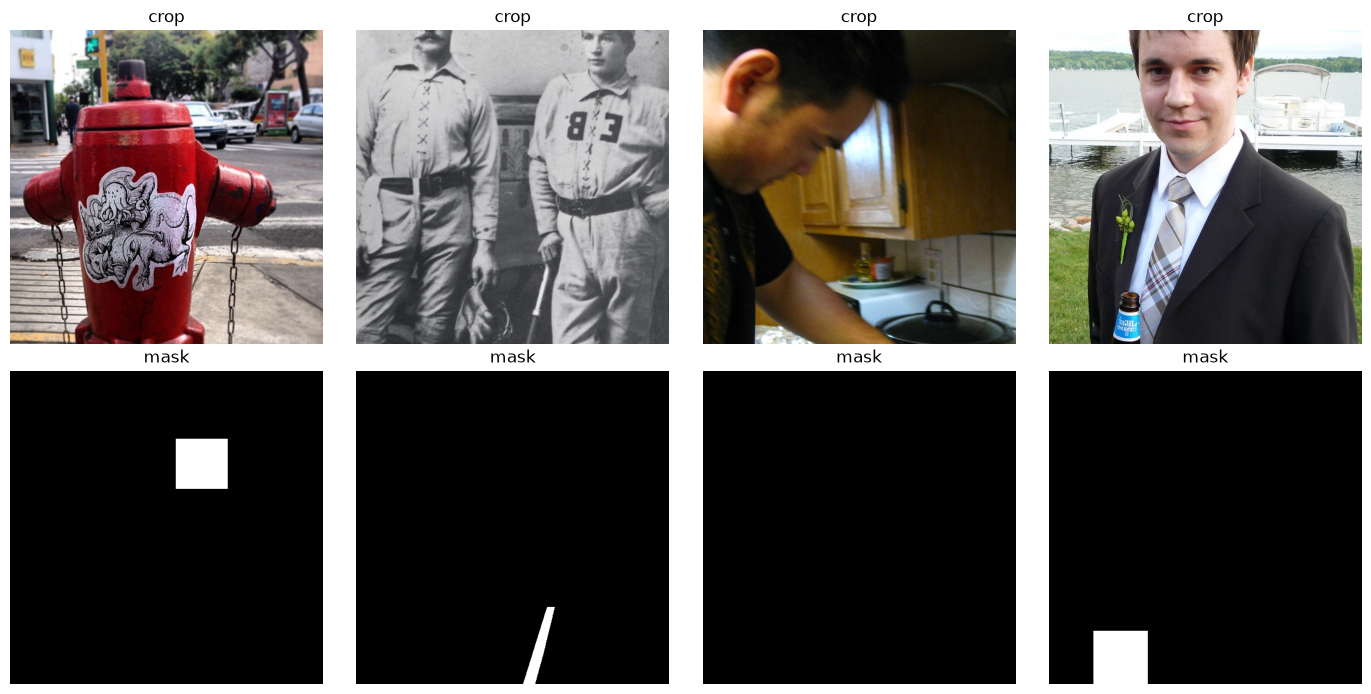

In [5]:
# ============================================================
# 5. Training dataset: native-resolution random crops
# ============================================================
from torch.utils.data import Dataset, DataLoader

class CropDataset(Dataset):
    def __init__(self, store, indices, crop, pos_prob):
        self.store, self.indices, self.crop, self.pos_prob = store, np.asarray(indices), crop, pos_prob
    def __len__(self): return len(self.indices)
    def __getitem__(self, k):
        i = int(self.indices[k]); c = self.crop
        img, msk = self.store.image(i), self.store.mask(i)
        H, W = msk.shape
        if H < c or W < c:  # pad small images
            ph, pw = max(0, c - H), max(0, c - W)
            img = np.pad(img, ((0, ph), (0, pw), (0, 0))); msk = np.pad(msk, ((0, ph), (0, pw)))
            H, W = msk.shape
        pos = self.store.pos[i]; pos = pos[pos[:, 0] >= 0]
        if len(pos) and np.random.rand() < self.pos_prob:
            y, x = pos[np.random.randint(len(pos))]
            y0 = int(np.clip(y - np.random.randint(c), 0, H - c))   # guarantees (y, x) is inside the crop
            x0 = int(np.clip(x - np.random.randint(c), 0, W - c))
        else:
            y0, x0 = np.random.randint(H - c + 1), np.random.randint(W - c + 1)
        img = img[y0:y0 + c, x0:x0 + c]; msk = msk[y0:y0 + c, x0:x0 + c]
        if np.random.rand() < 0.5:
            img, msk = img[:, ::-1], msk[:, ::-1]
        return (torch.from_numpy(np.ascontiguousarray(img.transpose(2, 0, 1))),          # uint8 -> normalised on GPU
                torch.from_numpy(np.ascontiguousarray(msk)[None].astype(np.float32)))

def worker_init(worker_id):
    np.random.seed((torch.initial_seed() + worker_id) % 2**32)

train_ds = CropDataset(store, train_rows, CFG["CROP"], CFG["POS_CROP_PROB"])
train_loader = DataLoader(train_ds, batch_size=CFG["BATCH_SIZE"], shuffle=True, drop_last=True,
                          num_workers=CFG["NUM_WORKERS"], pin_memory=(device.type == "cuda"),
                          persistent_workers=CFG["NUM_WORKERS"] > 0, worker_init_fn=worker_init)

xb, yb = next(iter(train_loader))
print("Batch:", tuple(xb.shape), xb.dtype, "| mask", tuple(yb.shape),
      f"| positive pixel fraction in crops: {yb.mean().item()*100:.2f}%")
fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for j in range(min(4, len(xb))):
    ax[0, j].imshow(xb[j].permute(1, 2, 0).numpy()); ax[0, j].set_title("crop"); ax[0, j].axis("off")
    ax[1, j].imshow(yb[j, 0].numpy(), cmap="gray"); ax[1, j].set_title("mask"); ax[1, j].axis("off")
plt.tight_layout(); plt.show()

In [6]:
# ============================================================
# 6. Model, loss, full-image inference + evaluation helpers
# ============================================================
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1) * 255
STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1) * 255
USE_AMP = device.type == "cuda"
THRS = np.round(np.r_[0.01, 0.02, 0.03, 0.04, np.arange(0.05, 0.951, 0.05)], 2)   # thresholds tried on validation
N_BINS = 1000                                        # histogram bins for pixel AUC / AP

def make_model(weights):
    m = smp.create_model(arch=CFG["ARCH"], encoder_name=CFG["ENCODER"], encoder_weights=weights,
                         in_channels=3, classes=1)
    return m.to(device).to(memory_format=torch.channels_last)

def normalise(x_uint8):
    return ((x_uint8.to(device, non_blocking=True).float() - MEAN) / STD).contiguous(memory_format=torch.channels_last)

class BCEDiceLoss(nn.Module):
    def __init__(self, pos_weight):
        super().__init__()
        self.register_buffer("pw", torch.tensor([pos_weight]))
    def forward(self, logits, target):
        logits = logits.float()
        bce = F.binary_cross_entropy_with_logits(logits, target, pos_weight=self.pw)
        p = torch.sigmoid(logits)
        dice = (2 * (p * target).sum() + 1.0) / (p.sum() + target.sum() + 1.0)   # batch-level soft Dice
        return bce + (1.0 - dice)

@torch.no_grad()
def predict_prob(model, img_uint8, tta=False):
    # Full-resolution probability map (H, W) for one HxWx3 uint8 image
    H, W = img_uint8.shape[:2]
    x = normalise(torch.from_numpy(np.array(img_uint8)).permute(2, 0, 1)[None])   # np.array -> writable copy
    ph, pw = (-H) % 32, (-W) % 32
    if ph or pw:
        x = F.pad(x, (0, pw, 0, ph), mode="reflect")
    with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
        prob = torch.sigmoid(model(x).float())
        if tta:
            prob = 0.5 * (prob + torch.sigmoid(model(x.flip(-1)).float()).flip(-1))
    return prob[0, 0, :H, :W]

@torch.no_grad()
def run_eval(model, indices, tta=False, desc="Eval"):
    # Per-image pixel counts at every threshold + soft area + global histograms
    model.eval()
    torch.backends.cudnn.benchmark = False            # image sizes vary
    thr = torch.tensor(THRS, device=device, dtype=torch.float32).view(-1, 1, 1)
    n = len(indices)
    out = dict(inter=np.zeros((n, len(THRS))), pred=np.zeros((n, len(THRS))), gt=np.zeros(n),
               npx=np.zeros(n), soft=np.zeros(n),
               hpos=torch.zeros(N_BINS, device=device), hneg=torch.zeros(N_BINS, device=device))
    for k, i in enumerate(tqdm(indices, desc=desc, leave=False)):
        p = predict_prob(model, store.image(int(i)), tta=tta)
        g = torch.from_numpy(np.array(store.mask(int(i)))).to(device).bool()
        pred = p.unsqueeze(0) >= thr
        out["inter"][k] = (pred & g).sum((1, 2)).cpu().numpy()
        out["pred"][k]  = pred.sum((1, 2)).cpu().numpy()
        out["gt"][k], out["npx"][k], out["soft"][k] = g.sum().item(), g.numel(), p.sum().item()
        out["hpos"] += torch.histc(p[g],  bins=N_BINS, min=0, max=1)
        out["hneg"] += torch.histc(p[~g], bins=N_BINS, min=0, max=1)
    out["hpos"], out["hneg"] = out["hpos"].cpu().numpy(), out["hneg"].cpu().numpy()
    torch.backends.cudnn.benchmark = True
    return out

def loc_metrics(ev, t_index):
    I, P, G = ev["inter"][:, t_index], ev["pred"][:, t_index], ev["gt"]
    eps = 1e-9
    per_f1  = 2 * I / (P + G + eps)
    per_iou = I / (P + G - I + eps)
    tp_hist, fp_hist = np.cumsum(ev["hpos"][::-1]), np.cumsum(ev["hneg"][::-1])   # descending thresholds
    tpr = np.r_[0, tp_hist / max(tp_hist[-1], 1)]; fpr = np.r_[0, fp_hist / max(fp_hist[-1], 1)]
    prec = tp_hist / np.maximum(tp_hist + fp_hist, 1)
    ap = float(np.sum(np.diff(tpr) * prec))
    return {
        "threshold": float(THRS[t_index]),
        "F1_per_image_mean": float(per_f1.mean()),
        "IoU_per_image_mean": float(per_iou.mean()),
        "F1_global": float(2 * I.sum() / (P.sum() + G.sum() + eps)),
        "IoU_global": float(I.sum() / (P.sum() + G.sum() - I.sum() + eps)),
        "Precision_global": float(I.sum() / (P.sum() + eps)),
        "Recall_global": float(I.sum() / (G.sum() + eps)),
        "Pixel_AUC": float(np.trapezoid(tpr, fpr) if hasattr(np, "trapezoid") else np.trapz(tpr, fpr)),
        "Pixel_AP": ap,
    }, per_f1, per_iou

def best_threshold_index(ev):
    I, P, G = ev["inter"], ev["pred"], ev["gt"][:, None]
    return int(np.argmax((2 * I / (P + G + 1e-9)).mean(0)))   # maximise mean per-image F1

model = make_model(CFG["ENCODER_WEIGHTS"])
print(f'{CFG["ARCH"]}-{CFG["ENCODER"]}: {sum(p.numel() for p in model.parameters())/1e6:.1f} M parameters')

Unet-resnet34: 24.4 M parameters


Epoch 1/25:   0%|          | 0/356 [00:00<?, ?it/s]

Validation:   0%|          | 0/131 [00:00<?, ?it/s]

Ep 01 | loss 1.3962 | val F1 0.1266 IoU 0.0768 F1g 0.1258 AUC 0.7180 @thr 0.95 | 3.1 min  *best*


Epoch 2/25:   0%|          | 0/356 [00:00<?, ?it/s]

Validation:   0%|          | 0/131 [00:00<?, ?it/s]

Ep 02 | loss 1.1664 | val F1 0.2471 IoU 0.1788 F1g 0.3077 AUC 0.8487 @thr 0.50 | 2.7 min  *best*


... (65 outputs left out)

Ep 24 | loss 0.1333 | val F1 0.4896 IoU 0.4244 F1g 0.7931 AUC 0.9586 @thr 0.35 | 2.6 min  *best*


Epoch 25/25:   0%|          | 0/356 [00:00<?, ?it/s]

Validation:   0%|          | 0/131 [00:00<?, ?it/s]

Ep 25 | loss 0.1376 | val F1 0.4786 IoU 0.4071 F1g 0.7651 AUC 0.9560 @thr 0.15 | 2.6 min


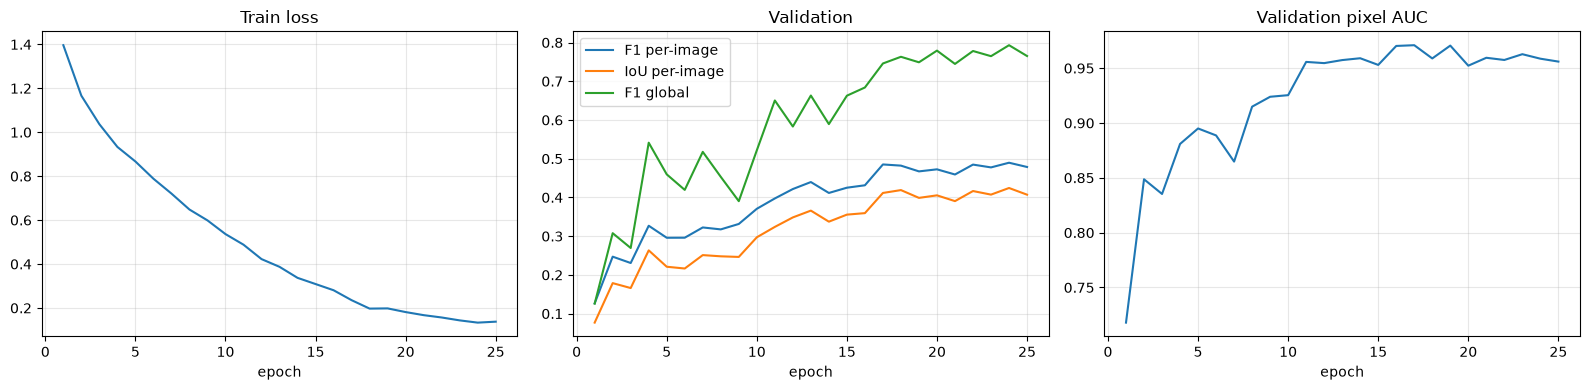

In [7]:
# ============================================================
# 7. Training (AMP, warmup + cosine LR, best/last checkpoints, auto-resume, early stopping)
# ============================================================
criterion = BCEDiceLoss(CFG["POS_WEIGHT"]).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=CFG["LR"], weight_decay=CFG["WEIGHT_DECAY"])
steps_per_epoch = len(train_loader)
total_steps, warm_steps = CFG["EPOCHS"] * steps_per_epoch, CFG["WARMUP_EPOCHS"] * steps_per_epoch
def lr_lambda(step):
    if step < warm_steps:
        return (step + 1) / warm_steps
    prog = (step - warm_steps) / max(1, total_steps - warm_steps)
    return 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * min(1.0, prog)))
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
scaler = torch.amp.GradScaler(device.type, enabled=USE_AMP)

start_epoch, best_score, bad_epochs, history = 0, -1.0, 0, []
if LAST_CKPT.exists():
    ck = torch.load(LAST_CKPT, map_location=device, weights_only=False)
    model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"])
    scheduler.load_state_dict(ck["scheduler"]); scaler.load_state_dict(ck["scaler"])
    start_epoch, best_score, bad_epochs, history = ck["epoch"], ck["best_score"], ck["bad_epochs"], ck["history"]
    print(f"Resumed from epoch {start_epoch} (best val F1 so far {best_score:.4f})")

torch.backends.cudnn.benchmark = True
session_start = time.time()
for epoch in range(start_epoch, CFG["EPOCHS"]):
    if bad_epochs >= CFG["PATIENCE"]:
        print("Early stopping triggered."); break
    if CFG["MAX_TRAIN_MINUTES"] and (time.time() - session_start) / 60 > CFG["MAX_TRAIN_MINUTES"]:
        print(f"Time budget of {CFG['MAX_TRAIN_MINUTES']} min reached after epoch {epoch}. "
              "Evaluating the best model so far; re-run the notebook later to continue training."); break
    model.train(); t0 = time.time(); run_loss = 0.0
    bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{CFG['EPOCHS']}", leave=False)
    for x, y in bar:
        x, y = normalise(x), y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(x)
        loss = criterion(logits, y)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer); scaler.update(); scheduler.step()
        run_loss += loss.item(); bar.set_postfix(loss=f"{loss.item():.3f}")
    train_loss = run_loss / steps_per_epoch

    ev = run_eval(model, val_idx, tta=False, desc="Validation")
    ti = best_threshold_index(ev); m, _, _ = loc_metrics(ev, ti)
    score = m["F1_per_image_mean"]
    history.append(dict(epoch=epoch + 1, train_loss=train_loss, lr=optimizer.param_groups[0]["lr"],
                        val_f1=score, val_iou=m["IoU_per_image_mean"], val_f1_global=m["F1_global"],
                        val_auc=m["Pixel_AUC"], val_thr=m["threshold"], minutes=(time.time() - t0) / 60))
    improved = score > best_score
    if improved:
        best_score, bad_epochs = score, 0
        torch.save({"model": model.state_dict(), "cfg": CFG, "epoch": epoch + 1, "val_metrics": m}, BEST_CKPT)
    else:
        bad_epochs += 1
    torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
                "scaler": scaler.state_dict(), "epoch": epoch + 1, "best_score": best_score,
                "bad_epochs": bad_epochs, "history": history, "cfg": CFG}, LAST_CKPT)
    print(f"Ep {epoch+1:02d} | loss {train_loss:.4f} | val F1 {score:.4f} IoU {m['IoU_per_image_mean']:.4f} "
          f"F1g {m['F1_global']:.4f} AUC {m['Pixel_AUC']:.4f} @thr {m['threshold']:.2f} | "
          f"{(time.time()-t0)/60:.1f} min" + ("  *best*" if improved else ""))

hist_df = pd.DataFrame(history); hist_df.to_csv(RUN_RESULTS_DIR / "training_history.csv", index=False)
if len(hist_df):
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    ax[0].plot(hist_df.epoch, hist_df.train_loss); ax[0].set_title("Train loss")
    ax[1].plot(hist_df.epoch, hist_df.val_f1, label="F1 per-image"); ax[1].plot(hist_df.epoch, hist_df.val_iou, label="IoU per-image")
    ax[1].plot(hist_df.epoch, hist_df.val_f1_global, label="F1 global"); ax[1].legend(); ax[1].set_title("Validation")
    ax[2].plot(hist_df.epoch, hist_df.val_auc); ax[2].set_title("Validation pixel AUC")
    for a in ax: a.set_xlabel("epoch"); a.grid(alpha=.3)
    plt.tight_layout(); plt.savefig(RUN_RESULTS_DIR / "training_curves.png", dpi=120); plt.show()

Best checkpoint: epoch 24


Validation (final):   0%|          | 0/131 [00:00<?, ?it/s]

Test:   0%|          | 0/141 [00:00<?, ?it/s]

Threshold chosen on validation: 0.25
            threshold  F1_per_image_mean  IoU_per_image_mean  F1_global  \
Validation       0.25             0.5053              0.4328     0.7843   
Test             0.25             0.5466              0.4673     0.7293   

            IoU_global  Precision_global  Recall_global  Pixel_AUC  Pixel_AP  
Validation      0.6451            0.7247         0.8546     0.9661    0.8638  
Test            0.5740            0.6533         0.8254     0.9668    0.8200  
(Test F1 at fixed 0.5 threshold: 0.5146)


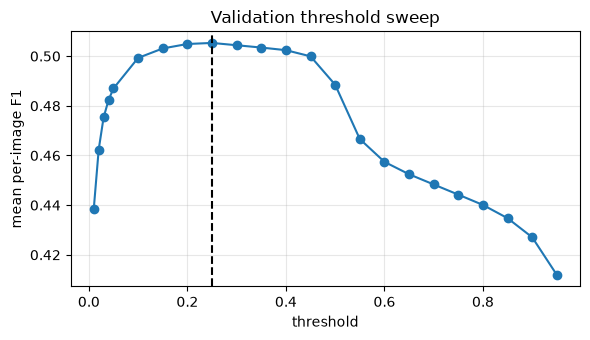

In [8]:
# ============================================================
# 8. LOCALIZATION results: tune threshold on VALIDATION, report on TEST
# ============================================================
ck = torch.load(BEST_CKPT, map_location=device, weights_only=False)
model = make_model(None); model.load_state_dict(ck["model"]); model.eval()
print("Best checkpoint: epoch", ck["epoch"])

ev_val  = run_eval(model, val_idx,  tta=CFG["TTA"], desc="Validation (final)")
ev_test = run_eval(model, test_idx, tta=CFG["TTA"], desc="Test")

T_IDX = best_threshold_index(ev_val); BEST_THR = float(THRS[T_IDX])
val_m,  val_f1,  val_iou  = loc_metrics(ev_val,  T_IDX)
test_m, test_f1, test_iou = loc_metrics(ev_test, T_IDX)
_, test_f1_05, _ = loc_metrics(ev_test, int(np.argmin(np.abs(THRS - 0.5))))

loc_table = pd.DataFrame({"Validation": val_m, "Test": test_m}).T
print(f"Threshold chosen on validation: {BEST_THR}")
display(loc_table.round(4)) if "display" in globals() else print(loc_table.round(4))
print(f"(Test F1 at fixed 0.5 threshold: {test_f1_05.mean():.4f})")

# F1 vs threshold curve (validation)
f1_curve = (2 * ev_val["inter"] / (ev_val["pred"] + ev_val["gt"][:, None] + 1e-9)).mean(0)
plt.figure(figsize=(6, 3.5)); plt.plot(THRS, f1_curve, marker="o"); plt.axvline(BEST_THR, ls="--", c="k")
plt.xlabel("threshold"); plt.ylabel("mean per-image F1"); plt.title("Validation threshold sweep"); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(RUN_RESULTS_DIR / "val_threshold_sweep.png", dpi=120); plt.show()

Estimator selected on validation MAE: Hard mask @MAE-thr 0.70
Baseline (always predict the train-set median area): test MAE = 2.711 pp
                                        MAE_pp  MedianAE_pp  RMSE_pp  Bias_pp  \
Estimator                   Split                                               
Hard mask @F1-thr 0.25      Validation   1.551        0.693    2.751    0.724   
                            Test         1.742        0.787    3.342    0.826   
Hard mask @MAE-thr 0.70     Validation   1.106        0.649    1.695   -0.532   
                            Test         1.473        0.769    2.300   -0.820   
Soft (mean probability)     Validation   1.179        0.573    1.986    0.179   
                            Test         1.439        0.647    2.452    0.058   
Soft + isotonic calibration Validation   1.228        0.778    1.825    0.020   
                            Test         1.477        0.939    2.358    0.018   
Hard + isotonic calibration Validation   1.371        0

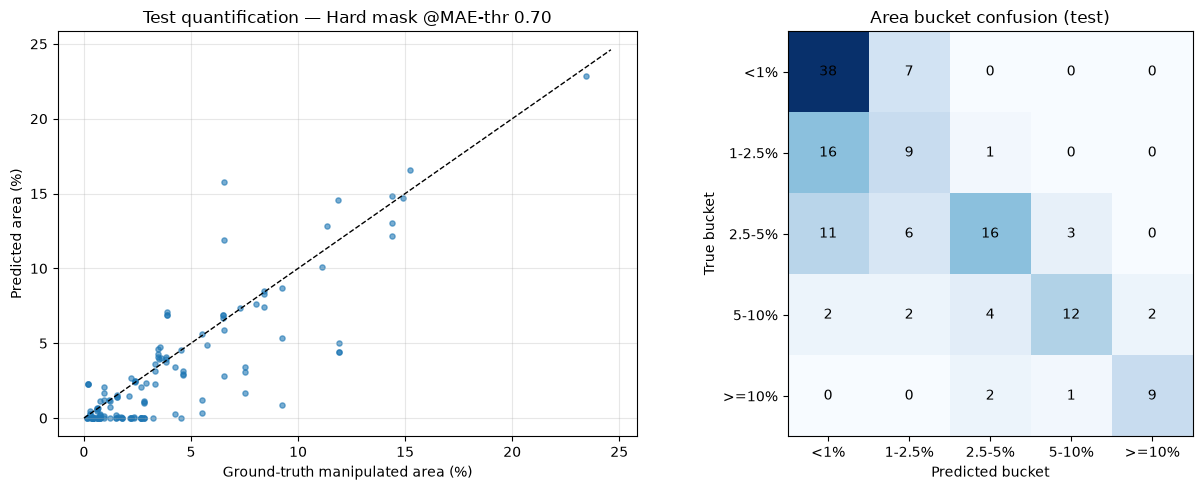

In [9]:
# ============================================================
# 9. QUANTIFICATION: how much of the image is AI-generated?
#    Several estimators; calibrated ones are cross-validated on val (grouped by source) -> honest selection
# ============================================================
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import GroupKFold
from scipy.stats import pearsonr, spearmanr

def areas(ev):
    npx = ev["npx"]
    return dict(gt=100 * ev["gt"] / npx, hard=100 * ev["pred"] / npx[:, None],   # hard: (n_images, n_thresholds)
                soft=100 * ev["soft"] / npx)

A_val, A_test = areas(ev_val), areas(ev_test)
T_MAE = int(np.argmin(np.abs(A_val["hard"] - A_val["gt"][:, None]).mean(0)))   # threshold that minimises val area MAE

def iso_fit_predict(x_tr, y_tr, x_te):
    iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=100).fit(x_tr, y_tr)
    return iso.predict(x_te)

def iso_cv(x, y, groups, k=5):
    n_splits = min(k, len(np.unique(groups)))
    if n_splits < 2:                       # too few source images for cross-validation
        return iso_fit_predict(x, y, x)
    pred = np.zeros_like(y)
    for tr, te in GroupKFold(n_splits=n_splits).split(x, y, groups):
        pred[te] = iso_fit_predict(x[tr], y[tr], x[te])
    return pred

g_val = source_ids[val_idx]
estimators = {
    f"Hard mask @F1-thr {THRS[T_IDX]:.2f}":  (A_val["hard"][:, T_IDX], A_test["hard"][:, T_IDX]),
    f"Hard mask @MAE-thr {THRS[T_MAE]:.2f}": (A_val["hard"][:, T_MAE], A_test["hard"][:, T_MAE]),
    "Soft (mean probability)":               (A_val["soft"], A_test["soft"]),
    "Soft + isotonic calibration":           (iso_cv(A_val["soft"], A_val["gt"], g_val),
                                              iso_fit_predict(A_val["soft"], A_val["gt"], A_test["soft"])),
    "Hard + isotonic calibration":           (iso_cv(A_val["hard"][:, T_IDX], A_val["gt"], g_val),
                                              iso_fit_predict(A_val["hard"][:, T_IDX], A_val["gt"], A_test["hard"][:, T_IDX])),
}

BUCKETS = [0, 1, 2.5, 5, 10, 100.01]
BUCKET_NAMES = ["<1%", "1-2.5%", "2.5-5%", "5-10%", ">=10%"]
def bucket(a): return np.clip(np.digitize(a, BUCKETS) - 1, 0, len(BUCKET_NAMES) - 1)

def quant_metrics(pred, gt):
    err = pred - gt
    return {"MAE_pp": np.abs(err).mean(), "MedianAE_pp": np.median(np.abs(err)), "RMSE_pp": np.sqrt((err**2).mean()),
            "Bias_pp": err.mean(), "Within_1pp_%": 100 * (np.abs(err) <= 1).mean(),
            "Within_2pp_%": 100 * (np.abs(err) <= 2).mean(),
            "Pearson_r": pearsonr(pred, gt)[0] if pred.std() > 0 else np.nan,
            "Spearman_rho": spearmanr(pred, gt)[0] if pred.std() > 0 else np.nan,
            "R2": 1 - (err**2).sum() / ((gt - gt.mean())**2).sum() if gt.std() > 0 else np.nan,
            "Bucket_acc_%": 100 * (bucket(pred) == bucket(gt)).mean()}

rows_q = []
for name, (pv, pt) in estimators.items():
    rows_q.append({"Estimator": name, "Split": "Validation", **quant_metrics(pv, A_val["gt"])})
    rows_q.append({"Estimator": name, "Split": "Test", **quant_metrics(pt, A_test["gt"])})
quant_table = pd.DataFrame(rows_q)
BEST_EST = quant_table[quant_table.Split == "Validation"].sort_values("MAE_pp").iloc[0]["Estimator"]
print("Estimator selected on validation MAE:", BEST_EST)
print("Baseline (always predict the train-set median area): test MAE =",
      f'{np.abs(np.median(gt_area_all[train_idx]) - A_test["gt"]).mean():.3f} pp')
show = quant_table.set_index(["Estimator", "Split"]).round(3)
display(show) if "display" in globals() else print(show)

pred_area_test = estimators[BEST_EST][1]
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
mx = max(A_test["gt"].max(), pred_area_test.max()) * 1.05
ax[0].scatter(A_test["gt"], pred_area_test, s=14, alpha=.6); ax[0].plot([0, mx], [0, mx], "k--", lw=1)
ax[0].set_xlabel("Ground-truth manipulated area (%)"); ax[0].set_ylabel("Predicted area (%)")
ax[0].set_title(f"Test quantification — {BEST_EST}"); ax[0].grid(alpha=.3)
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(bucket(A_test["gt"]), bucket(pred_area_test), labels=range(len(BUCKET_NAMES)))
ax[1].imshow(cm, cmap="Blues")
ax[1].set_xticks(range(len(BUCKET_NAMES)), BUCKET_NAMES); ax[1].set_yticks(range(len(BUCKET_NAMES)), BUCKET_NAMES)
for (r, c), v in np.ndenumerate(cm): ax[1].text(c, r, v, ha="center", va="center")
ax[1].set_xlabel("Predicted bucket"); ax[1].set_ylabel("True bucket"); ax[1].set_title("Area bucket confusion (test)")
plt.tight_layout(); plt.savefig(RUN_RESULTS_DIR / "quantification_test.png", dpi=120); plt.show()

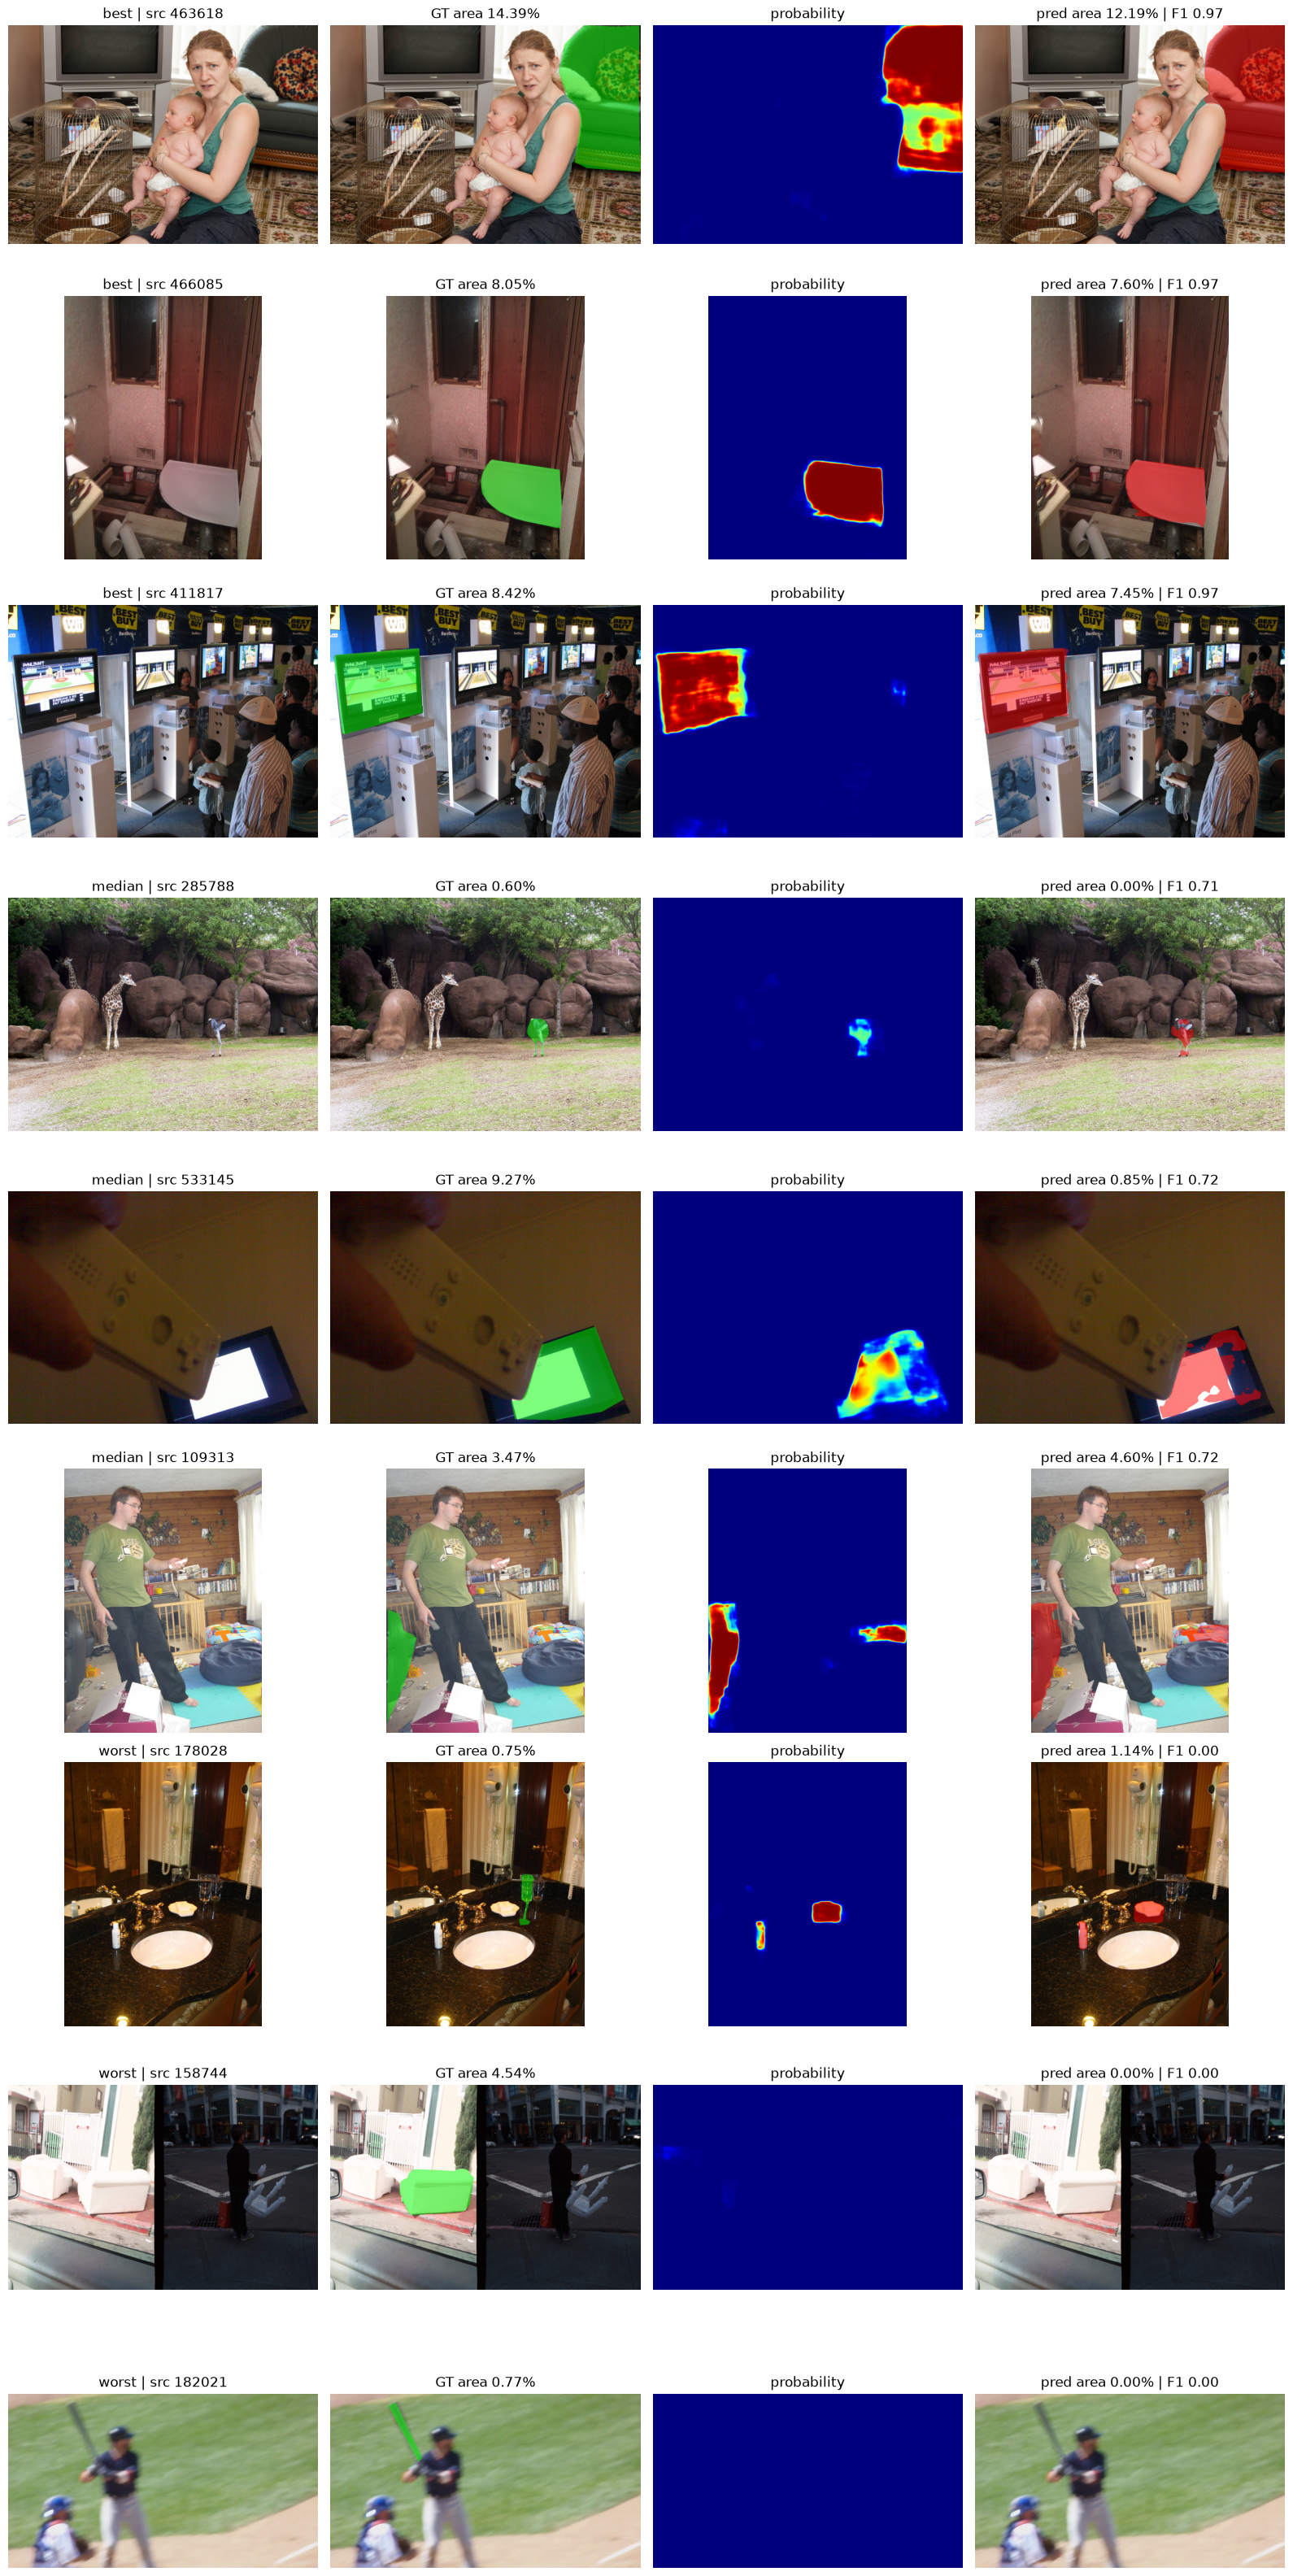

In [10]:
# ============================================================
# 10. Visual check: best / median / worst test images
# ============================================================
order = np.argsort(test_f1)
picks = list(order[-3:][::-1]) + list(order[len(order)//2 - 1: len(order)//2 + 2]) + list(order[:3])
labels = ["best"] * 3 + ["median"] * 3 + ["worst"] * 3
fig, axes = plt.subplots(len(picks), 4, figsize=(16, 3.6 * len(picks)))
for r, (k, lab) in enumerate(zip(picks, labels)):
    i = int(test_idx[k]); img = np.asarray(store.image(i)); gt = np.asarray(store.mask(i)).astype(bool)
    prob = predict_prob(model, img, tta=CFG["TTA"]).float().cpu().numpy(); pred = prob >= BEST_THR
    ov_gt = img.copy(); ov_gt[gt] = (0.5 * ov_gt[gt] + 0.5 * np.array([0, 255, 0])).astype(np.uint8)
    ov_pr = img.copy(); ov_pr[pred] = (0.5 * ov_pr[pred] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)
    for a, im, t in zip(axes[r], [img, ov_gt, prob, ov_pr],
                        [f"{lab} | src {source_ids[i]}", f"GT area {A_test['gt'][k]:.2f}%",
                         "probability", f"pred area {pred_area_test[k]:.2f}% | F1 {test_f1[k]:.2f}"]):
        a.imshow(im, cmap="jet" if t == "probability" else None, vmin=0, vmax=1 if t == "probability" else None)
        a.set_title(t); a.axis("off")
plt.tight_layout(); plt.savefig(RUN_RESULTS_DIR / "test_examples.png", dpi=100); plt.show()

In [11]:
# ============================================================
# 11. Save everything
# ============================================================
per_image = pd.DataFrame({
    "dataset_index": test_idx, "source_id": source_ids[test_idx],
    "manipulated_path": segm_df["manipulated_path"].to_numpy()[test_idx],
    "gt_area_pct": A_test["gt"], "pred_area_pct": pred_area_test,
    "abs_error_pp": np.abs(pred_area_test - A_test["gt"]),
    "f1": test_f1, "iou": test_iou,
})
per_image.to_csv(RUN_RESULTS_DIR / "test_per_image.csv", index=False)
loc_table.to_csv(RUN_RESULTS_DIR / "localization_metrics.csv")
quant_table.to_csv(RUN_RESULTS_DIR / "quantification_metrics.csv", index=False)

best_q_test = quant_table[(quant_table.Estimator == BEST_EST) & (quant_table.Split == "Test")].iloc[0]
summary = {"run": RUN_NAME, "best_epoch": int(ck["epoch"]), "threshold": BEST_THR,
           "quant_estimator": BEST_EST, **{f"test_{k}": v for k, v in test_m.items() if k != "threshold"},
           **{f"test_{k}": float(v) for k, v in best_q_test.items() if k not in ("Estimator", "Split")}}
json.dump({"summary": summary, "cfg": CFG}, open(RUN_RESULTS_DIR / "summary.json", "w"), indent=2, default=float)

runs_csv = LOC_RESULTS_DIR / "localization_runs.csv"
runs = pd.concat([pd.read_csv(runs_csv), pd.DataFrame([summary])]) if runs_csv.exists() else pd.DataFrame([summary])
runs.drop_duplicates("run", keep="last").to_csv(runs_csv, index=False)

# Everything needed to reuse the model + quantifier later
iso_soft = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=100).fit(A_val["soft"], A_val["gt"])
iso_hard = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=100).fit(A_val["hard"][:, T_IDX], A_val["gt"])
torch.save({"model": ck["model"], "cfg": CFG, "threshold": BEST_THR, "mae_threshold": float(THRS[T_MAE]),
            "quant_estimator": BEST_EST,
            "iso_soft": (iso_soft.X_thresholds_, iso_soft.y_thresholds_),
            "iso_hard": (iso_hard.X_thresholds_, iso_hard.y_thresholds_)},
           LOC_MODELS_DIR / f"{RUN_NAME}_deploy.pth")
print("Saved results to", RUN_RESULTS_DIR)
print(json.dumps(summary, indent=2, default=float))

Saved results to C:\AI_Image_Project\results\localization\Unet_resnet34_crop512_plusbbox_clean
{
  "run": "Unet_resnet34_crop512_plusbbox_clean",
  "best_epoch": 24,
  "threshold": 0.25,
  "quant_estimator": "Hard mask @MAE-thr 0.70",
  "test_F1_per_image_mean": 0.5466170859344234,
  "test_IoU_per_image_mean": 0.46734599342810307,
  "test_F1_global": 0.7293223060377472,
  "test_IoU_global": 0.5739632555943905,
  "test_Precision_global": 0.6532608197516093,
  "test_Recall_global": 0.8254300722158642,
  "test_Pixel_AUC": 0.9667664766311646,
  "test_Pixel_AP": 0.8199584484100342,
  "test_MAE_pp": 1.4731651137607518,
  "test_MedianAE_pp": 0.7693820529513888,
  "test_RMSE_pp": 2.3002807490016597,
  "test_Bias_pp": -0.8202409008695459,
  "test_Within_1pp_%": 57.446808510638306,
  "test_Within_2pp_%": 73.04964539007092,
  "test_Pearson_r": 0.8624820376244564,
  "test_Spearman_rho": 0.7341337803891054,
  "test_R2": 0.6677658981068098,
  "test_Bucket_acc_%": 59.57446808510638
}


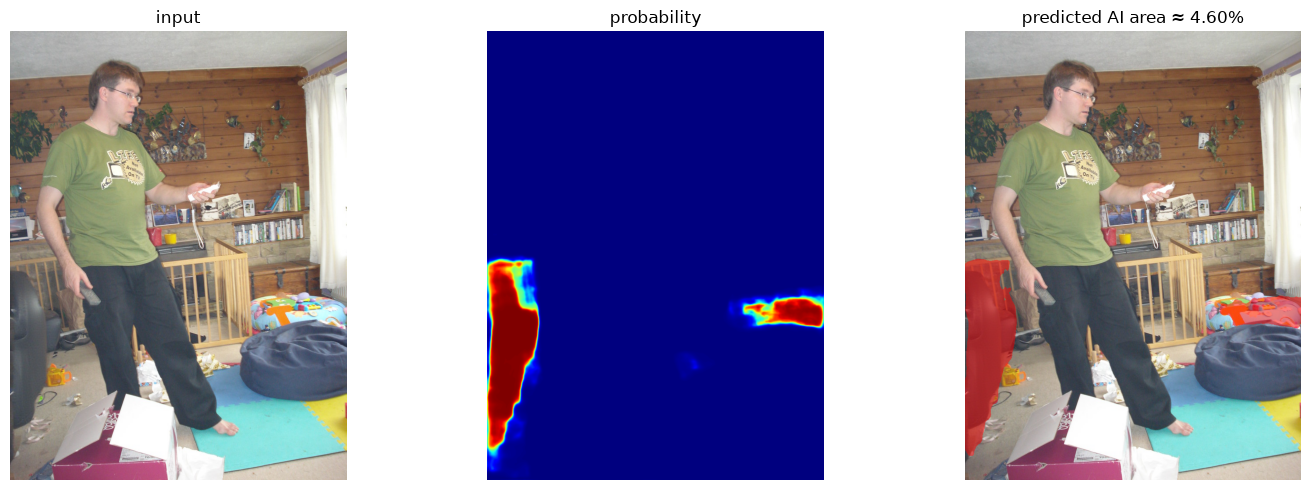

In [12]:
# ============================================================
# 12. Use it on any new image: mask + manipulated-area %
# ============================================================
def analyze_image(path, show=True):
    im = Image.open(path).convert("RGB")
    w, h = target_size(*im.size, CFG["MAX_SIDE"])
    if im.size != (w, h): im = im.resize((w, h), Image.Resampling.BICUBIC)
    img = np.asarray(im)
    prob = predict_prob(model, img, tta=CFG["TTA"]).float().cpu().numpy()
    mask = prob >= BEST_THR
    hard, soft = 100 * mask.mean(), 100 * prob.mean()
    est = {f"Hard mask @F1-thr {THRS[T_IDX]:.2f}": hard,
           f"Hard mask @MAE-thr {THRS[T_MAE]:.2f}": 100 * (prob >= THRS[T_MAE]).mean(),
           "Soft (mean probability)": soft,
           "Soft + isotonic calibration": float(iso_soft.predict([soft])[0]),
           "Hard + isotonic calibration": float(iso_hard.predict([hard])[0])}
    area = est[BEST_EST]
    if show:
        ov = img.copy(); ov[mask] = (0.5 * ov[mask] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)
        fig, ax = plt.subplots(1, 3, figsize=(15, 5))
        for a, x, t in zip(ax, [img, prob, ov], ["input", "probability", f"predicted AI area ≈ {area:.2f}%"]):
            a.imshow(x, cmap="jet" if t == "probability" else None); a.set_title(t); a.axis("off")
        plt.tight_layout(); plt.show()
    return {"mask": mask, "prob": prob, "area_pct": area}

_ = analyze_image(str(BASE_DIR / segm_df["manipulated_path"].iloc[int(test_idx[0])]))